In [1]:
import torch
import torchvision
from torchvision import transforms
from torchvision.transforms import functional as TF

from PIL import Image

import matplotlib.pyplot as plt

import cv2
import numpy as np

import onnx  # 1
import onnxruntime as ort # 2

import time

%matplotlib inline

In [2]:
# onnx_model = onnx.load("./VisualDrone.onnx")
# onnx.checker.check_model(onnx_model)

sess = ort.InferenceSession("./VisualDrone.onnx") # 3

obs_0 = sess.get_inputs()[0].name  # 4
obs_1 = sess.get_inputs()[1].name  # 5
recurrent_in = sess.get_inputs()[2].name  

transformer = transforms.Compose([
    transforms.Scale((128, 128))
])

cap = cv2.VideoCapture(0)

C:\Users\petch\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\torchvision\transforms\transforms.py:285: UserWarning: The use of the transforms.Scale transform is deprecated, please use transforms.Resize instead.
  warnings.warn("The use of the transforms.Scale transform is deprecated, " +


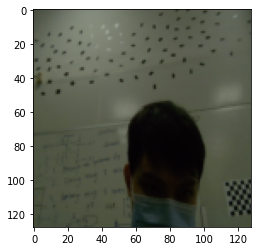

In [3]:
def imgProcessing(img):
    '''
    convert image to 128 * 128
    '''
    img = Image.fromarray(img)
    img = transformer(img)
    img = TF.to_tensor(img)
    img = img[[2, 1, 0], :, :].unsqueeze_(0)
    
    return np.array(img)

_, img = cap.read()
img = torchvision.transforms.ToPILImage()(torch.from_numpy(imgProcessing(img)).squeeze_(0))
plt.imshow(img)

In [4]:
# First Loop
_, img_init = cap.read()
np_img_init = imgProcessing(img_init)

obs_1_init = np.array(torch.tensor(np.random.rand(1, 17), dtype=torch.float32))
recurrent_in_init = np.array(torch.tensor(np.random.rand(1, 1, 256), dtype=torch.float32))

res = sess.run(None, {obs_0: np_img_init, obs_1: obs_1_init, recurrent_in: recurrent_in_init}) # 6

recurrent_out = res[4]

In [5]:
# Subsequent loops

tik = time.time()
time.sleep(0.1)

while True: 
    tok = time.time()
    fps = 1 / (tok - tik)
    tik = tok

    _, img = cap.read()
    np_img = imgProcessing(img)

    obs_1_ = np.array(torch.tensor(np.random.rand(1, 17), dtype=torch.float32))

    res = sess.run(None, {obs_0: np_img, obs_1: obs_1_, recurrent_in: np.array(recurrent_out)})

    recurrent_out = res[4]

    action = res[2] # 7
    print("FPS:", fps)
    print("Action:", action)

    cv2.imshow('', cv2.cvtColor(np_img[0, :, :, :].transpose(1, 2, 0), cv2.COLOR_BGR2RGB))

    if cv2.waitKey(25) & 0xFF == ord('q'):
        break
        

cap.release()
cv2.destroyAllWindows()

8.929941024931338
[[-1.         -1.          1.          0.37808713]]
9.090740427671648
[[-1. -1.  1. -1.]]
12.987230458638328
[[-1.        -0.5489314  1.        -0.505801 ]]
8.12868516322085
[[-1.         -1.          1.         -0.31743875]]
10.41874144565085
[[-0.75715446 -1.          1.         -1.        ]]
16.128960807235586
[[-1.        -0.3139502  1.        -1.       ]]
21.739579338011964
[[-1. -1.  1. -1.]]
16.39302897298903
[[-1.         -0.55110246  1.         -1.        ]]
10.526682478133745
[[-0.6606295  -0.21312769  1.          0.6179362 ]]
16.128154548355962
[[-0.59382385 -0.36595213  1.         -0.72788095]]
20.833187634109514
[[-1.         0.9805692  1.        -1.       ]]
15.873805955462707
[[-1.         -1.          1.         -0.58113176]]
20.83308415578481
[[-0.45081076 -0.7585371   1.         -1.        ]]
16.128898784459853
[[-1.         -1.          1.          0.08260528]]
21.2734972940896
[[-1.         -1.          1.         -0.32374796]]
16.131255985323698
[